In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

from tumor_treatment_opt.model import TreatmentSchedule
from tumor_treatment_opt.presets import get_config
from tumor_treatment_opt.radial_solver import solve_radial_model
from tumor_treatment_opt.solver import solve_model
from tumor_treatment_opt.optimization import TreatmentOptimizer, _lbfgs_starts
from tumor_treatment_opt.simulate import simulate
from tumor_treatment_opt.reparametrize import doses_from_fractions_numpy, fractions_from_doses

In [2]:
OVERRIDES = {"lumping": False}
config = get_config("adaptive", lumping=False, model="radial_jax", optimization_workers=1)
rng = np.random.default_rng(config.optimization_seed)

In [3]:
rng = np.random.default_rng(0)
num_doses = len(config.candidate_times)
parametrized_schedules = _lbfgs_starts(config, 0)
starting_results = [
    simulate(config, TreatmentSchedule(config.candidate_times, tuple(doses_from_fractions_numpy(theta, config))))
    for theta in parametrized_schedules
]
optimized_treatment = TreatmentOptimizer(config, method="lbfgs", starts=tuple(parametrized_schedules)).solve()

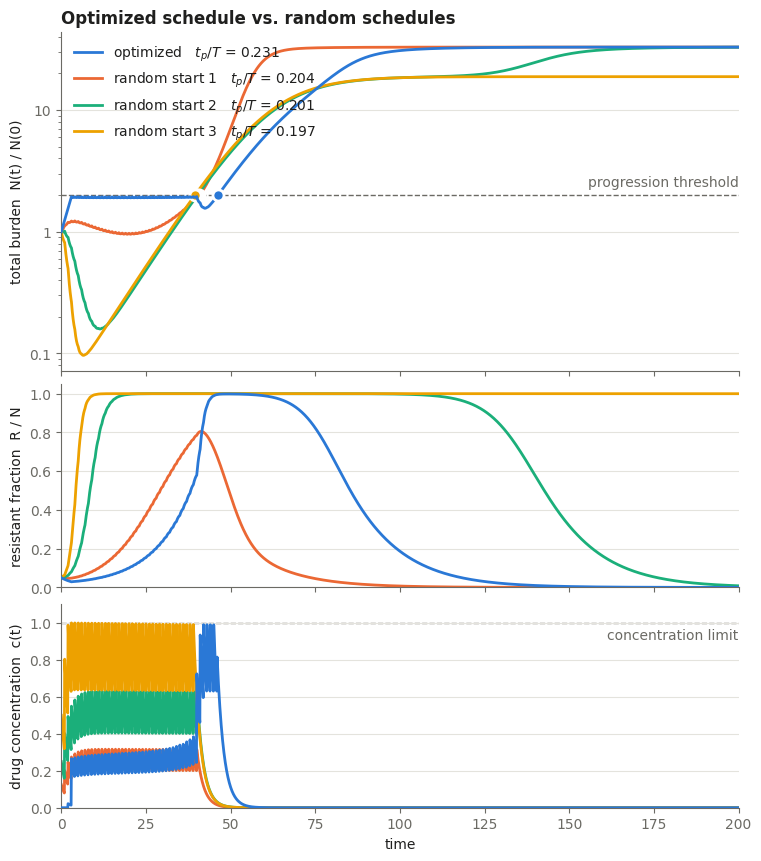

In [4]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # categorical slots 1-4: blue, orange, aqua, yellow
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e4e3dd"

def stop_after_progression(schedule, config):
    """The same schedule with every dose from the progression time on set to zero."""
    progression_time = simulate(config, schedule).outcomes.progression_time
    increments = tuple(
        0.0 if time >= progression_time else dose
        for time, dose in zip(schedule.times, schedule.increments)
    )
    return TreatmentSchedule(schedule.times, increments)


schedules = {
    "optimized": optimized_treatment.schedule,
    **{
        f"random start {i + 1}": TreatmentSchedule(
            config.candidate_times, tuple(doses_from_fractions_numpy(theta, config))
        )
        for i, theta in enumerate(parametrized_schedules)
    },
}
schedules = {name: stop_after_progression(schedule, config) for name, schedule in schedules.items()}
results = {name: simulate(config, schedule) for name, schedule in schedules.items()}

plt.rcParams.update({
    "font.size": 10, "axes.labelcolor": INK, "axes.edgecolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "legend.frameon": False,
})

fig, (ax_burden, ax_resistant, ax_drug) = plt.subplots(
    3, 1, figsize=(7.5, 8.5), sharex=True, constrained_layout=True,
    gridspec_kw={"height_ratios": [2.0, 1.2, 1.2]},
)
t_fine = np.linspace(0.0, config.final_time, 2000)

for (name, result), color in zip(results.items(), COLORS):
    burdens, outcomes = result.burdens, result.outcomes
    z = 4 if name == "optimized" else 2
    ax_burden.plot(burdens.times, burdens.total / burdens.total[0], color=color, lw=2, zorder=z,
                   label=f"{name}   $t_p/T$ = {outcomes.objective:.3f}")
    if np.isfinite(outcomes.progression_time):
        ax_burden.plot(outcomes.progression_time, config.progression_multiplier, "o", ms=8,
                       color=color, mec="white", mew=2, zorder=z + 1)
    ax_resistant.plot(burdens.times, burdens.resistant_fraction, color=color, lw=2, zorder=z)
    ax_drug.plot(t_fine, schedules[name].concentration(t_fine, config), color=color, lw=2, zorder=z)

ax_burden.axhline(config.progression_multiplier, color=MUTED, ls="--", lw=1, zorder=1)
ax_burden.annotate("progression threshold", (config.final_time, config.progression_multiplier),
                   xytext=(0, 4), textcoords="offset points", ha="right", va="bottom", color=MUTED)
ax_burden.set_ylabel("total burden  N(t) / N(0)")
ax_burden.set_yscale("log")
ax_burden.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax_burden.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax_burden.legend(loc="upper left", labelcolor=INK)
ax_burden.set_title("Optimized schedule vs. random schedules", loc="left", fontweight="bold")

ax_resistant.set_ylabel("resistant fraction  R / N")
ax_resistant.set_ylim(bottom=0)

ax_drug.axhline(1.0, color=MUTED, ls="--", lw=1, zorder=1)
ax_drug.annotate("concentration limit", (config.final_time, 1.0), xytext=(0, -4),
                 textcoords="offset points", ha="right", va="top", color=MUTED)
ax_drug.set_ylabel("drug concentration  c(t)")
ax_drug.set_ylim(0, 1.1)
ax_drug.set_xlabel("time")
ax_drug.set_xlim(0, config.final_time)

plt.show()
